In [3]:
# ---- CELL 1: Setup and load
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

FILE = "Ride_Sharing_Dataset_FIXED.csv"
df = pd.read_csv(FILE)

FARE = "Fare Amount (in $)"
DIST = "Ride Distance (in miles)"
RATING = "User Rating"

# Fix the column name typo
df = df.rename(columns={"Longtitude Dropoff": "Longitude Dropoff"})

df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")
print("Shape:", df.shape)
df.head()

Shape: (650, 17)


C:\Users\PC\AppData\Local\Temp\ipykernel_9428\185115185.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")


,Ride ID,Request Time,Pickup Location,Latitude Pickup,Longitude Pickup,Dropoff Location,Latitude Dropoff,Longitude Dropoff,Ride Distance (in miles),Fare Amount (in $),Payment Method,Driver ID,Vehicle Type,Traffic Condition,Peak Hours,Day of Week,User Rating
0,1.0,2022-05-18 03:49:00,"-1.369379,154.193063",-1.369379,154.193063,"30.877879,-46.862575",30.877879,-46.862575,7022.069283,722.21,PayPal,CV5232,Sedan,Medium,Yes,Wednesday,4.0
1,2.0,2023-05-10 13:27:00,"50.81867,11.962034",50.818670,11.962034,"-30.319864,-88.266464",-30.319864,-88.266464,4197.459385,439.75,PayPal,PG1364,SUV,Medium,Yes,Saturday,2.0
2,3.0,2024-01-21 14:12:00,"-31.012035,151.282883",-31.012035,151.282883,"51.650634,-171.505284",51.650634,-171.505284,5009.328711,520.93,Debit Card,WH4600,Sedan,Low,No,Monday,1.0
3,4.0,2022-06-04 17:00:00,"-77.187995,101.68942",-77.187995,101.689420,"-51.271029,-112.905338",-51.271029,-112.905338,11572.546740,1177.25,Apple Pay,CX2751,SUV,High,No,Friday,3.0
4,5.0,2022-03-24 10:17:00,"-54.567614,-88.054506",-54.567614,-88.054506,"-82.622689,6.226436",-82.622689,6.226436,2448.800085,264.88,PayPal,WP6729,SUV,Low,Yes,Thursday,4.0


In [4]:
# ---- CELL 2: Final data quality audit
audit = {
    "Missing values (total)":        int(df.isnull().sum().sum()),
    "Duplicate rows":                int(df.duplicated().sum()),
    "Duplicate Ride IDs":            int(df["Ride ID"].duplicated().sum()),
    "Duplicate Driver IDs":          int(df["Driver ID"].duplicated().sum()),
    "Invalid dates":                 int(df["Request Time"].isna().sum()),
    "Zero or negative fares":        int((df[FARE] <= 0).sum()),
    "Zero or negative distances":    int((df[DIST] <= 0).sum()),
    "Distances over 500 miles":      int((df[DIST] > 500).sum()),
    "Invalid ratings (not 1-5)":     int((~df[RATING].between(1, 5)).sum()),
}
print(pd.Series(audit).to_string())

print("\nDate range:", df["Request Time"].min(), "to", df["Request Time"].max())
print("Fare range:", df[FARE].min(), "to", df[FARE].max())
print("Distance range (miles):", round(df[DIST].min(), 1), "to", round(df[DIST].max(), 1))

for col in ["Vehicle Type", "Payment Method", "Traffic Condition", "Peak Hours"]:
    print(f"\n{col}:", sorted(df[col].dropna().unique()))

# Weekday consistency: stored column vs. timestamp
df["Weekday (derived)"] = df["Request Time"].dt.day_name()
match_rate = (df["Weekday (derived)"] == df["Day of Week"]).mean()
print(f"\n'Day of Week' column matches Request Time on {match_rate:.0%} of rows")

Missing values (total)        10200
Duplicate rows                  599
Duplicate Ride IDs              599
Duplicate Driver IDs            599
Invalid dates                   600
Zero or negative fares            0
Zero or negative distances        0
Distances over 500 miles         50
Invalid ratings (not 1-5)       600

Date range: 2022-01-02 14:51:00 to 2024-12-28 17:14:00
Fare range: 72.51 to 1233.21
Distance range (miles): 525.1 to 12132.1

Vehicle Type: ['Bus', 'Motorcycle', 'SUV', 'Sedan']

Payment Method: ['Apple Pay', 'Cash', 'Debit Card', 'PayPal', 'Visa']

Traffic Condition: ['High', 'Low', 'Medium']

Peak Hours: ['No', 'Yes']

'Day of Week' column matches Request Time on 1% of rows


In [5]:
# ---- CELL 3: Cleaning rules (documented in code)
# Rule 1: no rows excluded if the audit above shows zero missing/duplicate/invalid values.
before = len(df)
df = df.dropna(subset=["Ride ID", "Request Time", FARE, "Driver ID"])
df = df.drop_duplicates(subset=["Ride ID"])
df = df[df[FARE] >= 0]
print(f"Rows before: {before} | after: {len(df)} | excluded: {before - len(df)}")

# Rule 2: Ride Status is a PROXY (no status column exists): fare > 0 = Completed, fare = 0 = Cancelled
df["Ride Status"] = np.where(df[FARE] > 0, "Completed", "Cancelled")

# Rule 3: use weekday and hour derived from the timestamp, not the stored 'Day of Week'
df["Weekday"] = df["Request Time"].dt.day_name()
df["Hour"] = df["Request Time"].dt.hour
df["Month"] = df["Request Time"].dt.to_period("M").astype(str)

Rows before: 650 | after: 50 | excluded: 600


In [6]:
# ---- CELL 4: Executive KPIs (pandas)
total_rides = len(df)
completed = int((df[FARE] > 0).sum())
cancelled = total_rides - completed
total_revenue = df.loc[df[FARE] > 0, FARE].sum()

kpis = pd.Series({
    "Total Rides": total_rides,
    "Completed Rides": completed,
    "Cancelled Rides": cancelled,
    "Total Revenue ($)": round(total_revenue, 2),
    "Average Fare ($)": round(total_revenue / completed, 2),
    "Average Rating": round(df[RATING].mean(), 2),
    "Completion Rate (%)": round(completed / total_rides * 100, 1),
    "Cancellation Rate (%)": round(cancelled / total_rides * 100, 1),
    "Revenue per Completed Ride ($)": round(total_revenue / completed, 2),
    "Average Distance (miles)": round(df[DIST].mean(), 1),
})
print(kpis.to_string())

Total Rides                          50.00
Completed Rides                      50.00
Cancelled Rides                       0.00
Total Revenue ($)                 31788.97
Average Fare ($)                    635.78
Average Rating                        2.80
Completion Rate (%)                 100.00
Cancellation Rate (%)                 0.00
Revenue per Completed Ride ($)      635.78
Average Distance (miles)           6157.80


In [7]:
# ---- CELL 5: Independent validation with SQL (SQLite)
con = sqlite3.connect(":memory:")
sql_df = df.rename(columns={FARE: "fare", RATING: "rating"}).copy()
sql_df["Request Time"] = sql_df["Request Time"].astype(str)
sql_df.drop(columns=["Weekday (derived)"], errors="ignore").to_sql("rides", con, index=False)

sql = """
SELECT COUNT(*)                         AS total_rides,
       SUM(fare > 0)                    AS completed_rides,
       SUM(fare = 0)                    AS cancelled_rides,
       ROUND(SUM(fare), 2)              AS total_revenue,
       ROUND(SUM(fare) / SUM(fare > 0), 2) AS avg_fare,
       ROUND(AVG(rating), 2)            AS avg_rating
FROM rides;
"""
sql_result = pd.read_sql(sql, con)
print(sql_result.to_string(index=False))

checks = {
    "Total rides":     (total_rides, int(sql_result.total_rides[0])),
    "Completed rides": (completed, int(sql_result.completed_rides[0])),
    "Revenue":         (round(total_revenue, 2), float(sql_result.total_revenue[0])),
    "Average fare":    (round(total_revenue / completed, 2), float(sql_result.avg_fare[0])),
    "Average rating":  (round(df[RATING].mean(), 2), float(sql_result.avg_rating[0])),
}
for name, (a, b) in checks.items():
    print(f"{name:16} pandas={a:<12} SQL={b:<12} {'MATCH' if abs(a - b) < 0.005 else 'MISMATCH'}")

 total_rides  completed_rides  cancelled_rides  total_revenue  avg_fare  avg_rating
          50               50                0       31788.97    635.78         2.8
Total rides      pandas=50           SQL=50           MATCH
Completed rides  pandas=50           SQL=50           MATCH
Revenue          pandas=31788.97     SQL=31788.97     MATCH
Average fare     pandas=635.78       SQL=635.78       MATCH
Average rating   pandas=2.8          SQL=2.8          MATCH


Rides by weekday (from timestamps):
 Weekday
Monday        4
Tuesday       6
Wednesday     7
Thursday      6
Friday        5
Saturday     13
Sunday        9

Busiest weekday: Saturday | Busiest hour: 22

Peak Hours flag:
 Peak Hours
Yes    25
No     25

Peak revenue month: 2022-06 ($3,109.66)


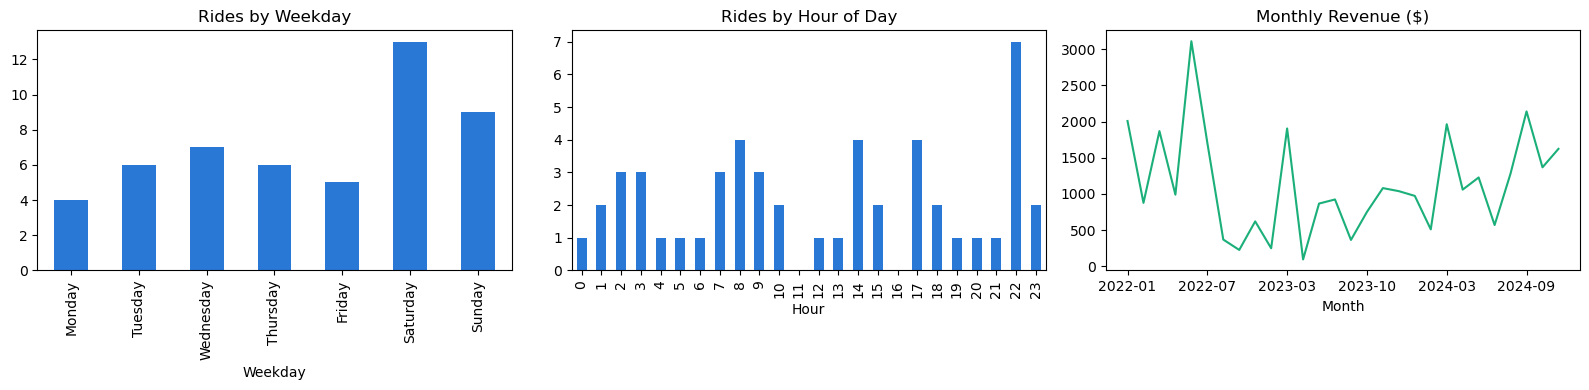

In [8]:
# ---- CELL 6: Demand analysis (corrected weekday + hour)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = df["Weekday"].value_counts().reindex(order).fillna(0).astype(int)
by_hour = df["Hour"].value_counts().reindex(range(24)).fillna(0).astype(int)
by_month = df.groupby("Month")[FARE].sum()

print("Rides by weekday (from timestamps):\n", by_weekday.to_string())
print("\nBusiest weekday:", by_weekday.idxmax(), "| Busiest hour:", by_hour.idxmax())
print("\nPeak Hours flag:\n", df["Peak Hours"].value_counts().to_string())
print(f"\nPeak revenue month: {by_month.idxmax()} (${by_month.max():,.2f})")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
by_weekday.plot.bar(ax=ax[0], color="#2a78d6", title="Rides by Weekday")
by_hour.plot.bar(ax=ax[1], color="#2a78d6", title="Rides by Hour of Day")
by_month.plot(ax=ax[2], color="#1baf7a", title="Monthly Revenue ($)")
plt.tight_layout(); plt.show()


=== Vehicle Type ===
              Rides  Revenue  Avg_Fare  Avg_Rating  Revenue %
Vehicle Type                                                 
Bus              15  9756.79    650.45        2.67       30.7
Sedan            17  9631.78    566.58        2.88       30.3
SUV              11  7049.18    640.83        2.91       22.2
Motorcycle        7  5351.22    764.46        2.71       16.8

=== Payment Method ===
                Rides  Revenue  Avg_Fare  Avg_Rating  Revenue %
Payment Method                                                 
Visa               14  9297.30    664.09        2.43       29.2
Debit Card         12  7986.17    665.51        3.08       25.1
Apple Pay           8  5330.14    666.27        2.75       16.8
Cash                8  5146.41    643.30        2.88       16.2
PayPal              8  4028.95    503.62        3.00       12.7

=== Traffic Condition ===
                   Rides   Revenue  Avg_Fare  Avg_Rating  Revenue %
Traffic Condition                      

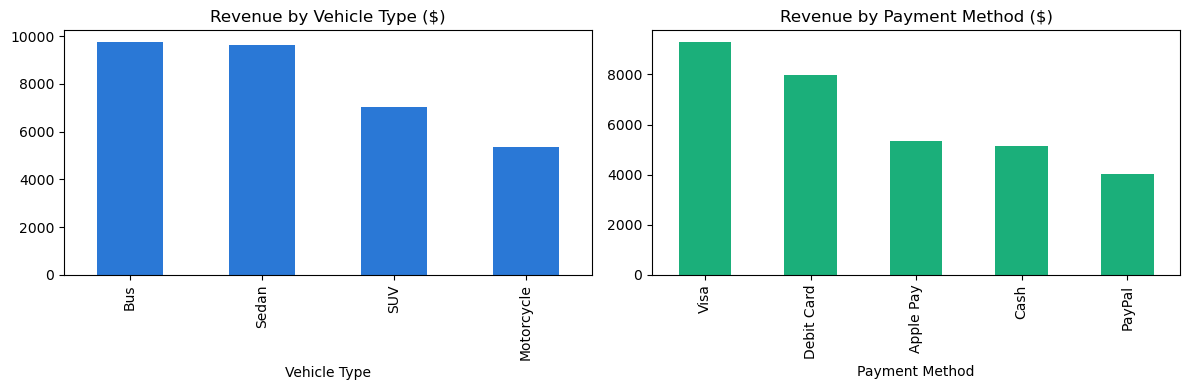

In [9]:
# ---- CELL 7: Revenue and segment analysis
def segment(col):
    g = df.groupby(col).agg(Rides=(FARE, "count"), Revenue=(FARE, "sum"),
                            Avg_Fare=(FARE, "mean"), Avg_Rating=(RATING, "mean"))
    g["Revenue %"] = (g.Revenue / g.Revenue.sum() * 100).round(1)
    return g.sort_values("Revenue", ascending=False).round(2)

for col in ["Vehicle Type", "Payment Method", "Traffic Condition"]:
    print(f"\n=== {col} ===")
    print(segment(col).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
segment("Vehicle Type").Revenue.plot.bar(ax=ax[0], color="#2a78d6", title="Revenue by Vehicle Type ($)")
segment("Payment Method").Revenue.plot.bar(ax=ax[1], color="#1baf7a", title="Revenue by Payment Method ($)")
plt.tight_layout(); plt.show()

In [10]:
# ---- CELL 8: Month-over-month comparison (time intelligence check)
monthly = df.groupby("Month")[FARE].sum().to_frame("Revenue")
monthly["Previous Month"] = monthly["Revenue"].shift(1)
monthly["Change ($)"] = monthly["Revenue"] - monthly["Previous Month"]
monthly["Change (%)"] = (monthly["Change ($)"] / monthly["Previous Month"] * 100).round(1)
print(monthly.round(2).to_string())
print(f"\nMonths with data: {len(monthly)} of 36 (gaps appear as missing months)")

         Revenue  Previous Month  Change ($)  Change (%)
Month                                                   
2022-01  2007.94             NaN         NaN         NaN
2022-02   877.66         2007.94    -1130.28       -56.3
2022-03  1868.44          877.66      990.78       112.9
2022-05   990.61         1868.44     -877.83       -47.0
2022-06  3109.66          990.61     2119.05       213.9
2022-07  1708.17         3109.66    -1401.49       -45.1
2022-08   370.71         1708.17    -1337.46       -78.3
2022-09   227.41          370.71     -143.30       -38.7
2022-11   621.77          227.41      394.36       173.4
2022-12   250.59          621.77     -371.18       -59.7
2023-03  1905.01          250.59     1654.42       660.2
2023-04    96.15         1905.01    -1808.86       -95.0
2023-05   867.87           96.15      771.72       802.6
2023-06   924.49          867.87       56.62         6.5
2023-07   365.44          924.49     -559.05       -60.5
2023-10   751.83          365.4

In [11]:
# ---- CELL 9: Ride-level segments (NOT customers - no Customer ID exists)
df["Fare Tier"] = pd.cut(df[FARE], [0, 300, 700, np.inf],
                         labels=["Low (<$300)", "Mid ($300-$700)", "High (>$700)"])
df["Rating Segment"] = pd.cut(df[RATING], [0, 2, 3, 5],
                              labels=["Low (1-2)", "Neutral (3)", "High (4-5)"])

for col in ["Fare Tier", "Rating Segment"]:
    g = df.groupby(col, observed=True).agg(Rides=(FARE, "count"), Revenue=(FARE, "sum"),
                                           Avg_Fare=(FARE, "mean"), Avg_Rating=(RATING, "mean"))
    g["% of Rides"] = (g.Rides / g.Rides.sum() * 100).round(1)
    g["% of Revenue"] = (g.Revenue / g.Revenue.sum() * 100).round(1)
    print(f"\n=== {col} (ride segments, not customers) ===")
    print(g.round(2).to_string())

print("\nRating distribution:\n", df[RATING].value_counts().sort_index().to_string())


=== Fare Tier (ride segments, not customers) ===
                 Rides   Revenue  Avg_Fare  Avg_Rating  % of Rides  % of Revenue
Fare Tier                                                                       
Low (<$300)          8   1341.48    167.68        2.75        16.0           4.2
Mid ($300-$700)     19   9396.84    494.57        2.68        38.0          29.6
High (>$700)        23  21050.65    915.25        2.91        46.0          66.2

=== Rating Segment (ride segments, not customers) ===
                Rides   Revenue  Avg_Fare  Avg_Rating  % of Rides  % of Revenue
Rating Segment                                                                 
Low (1-2)          23  14780.67    642.64        1.43        46.0          46.5
Neutral (3)         8   5231.45    653.93        3.00        16.0          16.5
High (4-5)         19  11776.85    619.83        4.37        38.0          37.0

Rating distribution:
 User Rating
1.0    13
2.0    10
3.0     8
4.0    12
5.0     7


In [12]:
# ---- CELL 10: Driver view and ranking (each driver has one ride)
drivers = df.groupby("Driver ID").agg(
    Rides=(FARE, "count"),
    Completed=(FARE, lambda s: (s > 0).sum()),
    Revenue=(FARE, "sum"),
    Rating=(RATING, "mean"),
).reset_index()
drivers["Completion Rate (%)"] = drivers.Completed / drivers.Rides * 100

def norm(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() != s.min() else s * 0

# Documented score: 30% revenue, 25% volume, 25% rating, 20% completion (min-max normalized)
drivers["Score"] = 100 * (0.30 * norm(drivers.Revenue) + 0.25 * norm(drivers.Rides) +
                          0.25 * norm(drivers.Rating) + 0.20 * norm(drivers["Completion Rate (%)"]))
benchmark = drivers.Score.mean()
drivers["Score vs Benchmark"] = drivers.Score - benchmark
drivers = drivers.sort_values("Score", ascending=False)

print(f"Drivers: {len(drivers)} | max rides per driver: {drivers.Rides.max()} | benchmark score: {benchmark:.2f}")
print("\nTop 5:\n", drivers.head(5).round(2).to_string(index=False))
print("\nBottom 5:\n", drivers.tail(5).round(2).to_string(index=False))
print("\nNote: every driver has one ride, so scores reflect single trips, not sustained performance.")

Drivers: 50 | max rides per driver: 1 | benchmark score: 25.81

Top 5:
 Driver ID  Rides  Completed  Revenue  Rating  Completion Rate (%)  Score  Score vs Benchmark
   OC1811      1          1  1159.06     4.0                100.0  46.83               21.02
   ET1257      1          1   867.26     5.0                100.0  45.54               19.73
   UB9840      1          1  1039.22     4.0                100.0  43.74               17.93
   QM3102      1          1   758.12     5.0                100.0  42.72               16.91
   XH6044      1          1   734.33     5.0                100.0  42.11               16.30

Bottom 5:
 Driver ID  Rides  Completed  Revenue  Rating  Completion Rate (%)  Score  Score vs Benchmark
   XO5724      1          1   484.57     1.0                100.0  10.65              -15.16
   RA8465      1          1   452.80     1.0                100.0   9.83              -15.98
   CB8894      1          1   365.44     1.0                100.0   7.57       

In [13]:
# ---- CELL 11: What-if scenario (estimate only)
rate_changes = [-0.10, -0.05, 0, 0.05, 0.10]
scenario = pd.DataFrame({
    "Rate Change": [f"{r:+.0%}" for r in rate_changes],
    "Estimated Revenue ($)": [round(total_revenue * (1 + r), 2) for r in rate_changes],
})
scenario["Change vs Current ($)"] = (scenario["Estimated Revenue ($)"] - round(total_revenue, 2)).round(2)
print(scenario.to_string(index=False))
print("\nEstimate only. Assumes ride volume and distance do not change when price changes (no demand elasticity).")
print("Distances in this dataset are implausible (525-12,132 miles), so do not use per-mile pricing conclusions.")

Rate Change  Estimated Revenue ($)  Change vs Current ($)
       -10%               28610.07               -3178.90
        -5%               30199.52               -1589.45
        +0%               31788.97                   0.00
        +5%               33378.42                1589.45
       +10%               34967.87                3178.90

Estimate only. Assumes ride volume and distance do not change when price changes (no demand elasticity).
Distances in this dataset are implausible (525-12,132 miles), so do not use per-mile pricing conclusions.


In [14]:
# ---- CELL 12: Remaining limitations (print for the report)
limitations = [
    "No Customer ID: customer segmentation, repeat behavior and lifetime value cannot be measured.",
    "No cancellations: Ride Status is a proxy based on fare > 0.",
    "Distances are implausible (all rides over 500 miles); distance-based findings are unreliable.",
    "Stored 'Day of Week' conflicts with Request Time; weekday is derived from the timestamp.",
    "Each driver has exactly one ride; driver rankings are single-trip snapshots.",
    "Pickup locations are unique global coordinates; no location ranking is possible.",
    "Small sample (n = 50); monthly trends are noisy.",
    "No cost data: no profitability claims.",
]
for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")

1. No Customer ID: customer segmentation, repeat behavior and lifetime value cannot be measured.
2. No cancellations: Ride Status is a proxy based on fare > 0.
3. Distances are implausible (all rides over 500 miles); distance-based findings are unreliable.
4. Stored 'Day of Week' conflicts with Request Time; weekday is derived from the timestamp.
5. Each driver has exactly one ride; driver rankings are single-trip snapshots.
6. Pickup locations are unique global coordinates; no location ranking is possible.
7. Small sample (n = 50); monthly trends are noisy.
8. No cost data: no profitability claims.


In [15]:
import pandas as pd
import numpy as np

FILE = "Ride_Sharing_Dataset_FIXED.csv"          # the ride-level file, NOT the driver file
df = pd.read_csv(FILE)
df.columns = df.columns.str.strip()
FARE, RATING = "Fare Amount (in $)", "User Rating"
need = ["Ride ID", "Request Time", "Driver ID", FARE, RATING,
        "Vehicle Type", "Traffic Condition", "Peak Hours"]
assert not [c for c in need if c not in df.columns], "Wrong file loaded (use the ride-level dataset)"

# Time features come from the timestamp, not the stored 'Day of Week' column
df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")
df["Weekday"] = df["Request Time"].dt.day_name()
df["Hour"] = df["Request Time"].dt.hour
df["Time Band"] = pd.cut(df["Hour"], [-1, 5, 11, 17, 23],
                         labels=["Night 00-05", "Morning 06-11", "Afternoon 12-17", "Evening 18-23"])
df["Low Rated"] = df[RATING] <= 2
df["Completed"] = df[FARE] > 0             # proxy: fare > 0 = completed

# ---------- DRIVER INTELLIGENCE ----------
d = df.groupby("Driver ID").agg(Rides=(FARE, "count"), Completed=("Completed", "sum"),
                                Revenue=(FARE, "sum"), Rating=(RATING, "mean")).reset_index()
d["Completion Rate"] = d.Completed / d.Rides * 100
d["Cancellation Rate"] = 100 - d["Completion Rate"]

def norm(s, lo=None, hi=None):
    lo = s.min() if lo is None else lo
    hi = s.max() if hi is None else hi
    return (s - lo) / (hi - lo) if hi != lo else s * 0

# Score: 30% revenue, 25% volume, 25% rating, 20% completion
d["Score"] = 100 * (0.30 * norm(d.Revenue) + 0.25 * norm(d.Rides) +
                    0.25 * norm(d.Rating, 1, 5) + 0.20 * norm(d["Completion Rate"]))
bench = d.Score.mean()
d["vs Benchmark"] = d.Score - bench
d = d.sort_values("Score", ascending=False).reset_index(drop=True)
d["Rank"] = d.index + 1

print("=== DRIVER BENCHMARKS ===")
print(f"Mean score {bench:.2f} | median {d.Score.median():.2f} | std {d.Score.std():.2f}")
print(f"Drivers below benchmark: {(d.Score < bench).sum()} of {len(d)}")
print(f"Drivers rated 1-2: {(d.Rating <= 2).sum()} | rated 4-5: {(d.Rating >= 4).sum()}")
print(f"Max rides per driver: {d.Rides.max()} (single-trip scores)")
print(f"Correlation revenue-rating: {d.Revenue.corr(d.Rating):.2f} | revenue-score: {d.Revenue.corr(d.Score):.2f}")
print(f"Highest possible score here: {30*1 + 25*1:.0f} (volume and completion are constant)")
cols = ["Rank", "Driver ID", "Revenue", "Rating", "Score", "vs Benchmark"]
print("\nTop 5\n", d.head(5)[cols].round(1).to_string(index=False))
print("\nBottom 5\n", d.tail(5)[cols].round(1).to_string(index=False))
print("\nAverage by rating\n", d.groupby("Rating").agg(Drivers=("Score", "count"),
      Avg_Revenue=("Revenue", "mean"), Avg_Score=("Score", "mean")).round(1).to_string())

# ---------- OPERATIONS INTELLIGENCE ----------
overall_low = df["Low Rated"].mean() * 100
print(f"\n=== OPERATIONS (completion {df.Completed.mean():.0%}, cancellations: {(~df.Completed).sum()}) ===")
print(f"Overall low-rated share (1-2 stars): {overall_low:.1f}%")

def ops(col):
    g = df.groupby(col, observed=True).agg(
        Rides=(FARE, "count"), Revenue=(FARE, "sum"), Avg_Fare=(FARE, "mean"),
        Avg_Rating=(RATING, "mean"), Low_Rated_Pct=("Low Rated", lambda s: s.mean() * 100))
    g["vs Overall (pts)"] = g.Low_Rated_Pct - overall_low
    g["Small sample"] = np.where(g.Rides < 10, "yes (<10 rides)", "")
    return g.round(2)

for col in ["Traffic Condition", "Time Band", "Weekday", "Vehicle Type", "Peak Hours"]:
    print(f"\n--- by {col} ---")
    print(ops(col).to_string())

# ---------- ATTENTION LIST ----------
parts = []
for col in ["Traffic Condition", "Time Band", "Weekday", "Vehicle Type"]:
    t = ops(col).reset_index().rename(columns={col: "Segment"})
    t.insert(0, "Dimension", col)
    parts.append(t)
att = pd.concat(parts)
att = att[att["vs Overall (pts)"] > 5].sort_values("vs Overall (pts)", ascending=False)
print("\n=== AREAS REQUIRING ATTENTION (low-rated share >5 pts above overall) ===")
print(att[["Dimension", "Segment", "Rides", "Revenue", "Avg_Rating",
           "Low_Rated_Pct", "vs Overall (pts)", "Small sample"]].to_string(index=False))
print("\nNOTE: associations only, not causes. Segments are small (n=50 total).")

=== DRIVER BENCHMARKS ===
Mean score 25.81 | median 25.80 | std 11.91
Drivers below benchmark: 25 of 50
Drivers rated 1-2: 23 | rated 4-5: 19
Max rides per driver: 1 (single-trip scores)
Correlation revenue-rating: -0.03 | revenue-score: 0.66
Highest possible score here: 55 (volume and completion are constant)

Top 5
  Rank Driver ID  Revenue  Rating  Score  vs Benchmark
    1    OC1811   1159.1     4.0   46.8          21.0
    2    ET1257    867.3     5.0   45.5          19.7
    3    UB9840   1039.2     4.0   43.7          17.9
    4    QM3102    758.1     5.0   42.7          16.9
    5    XH6044    734.3     5.0   42.1          16.3

Bottom 5
  Rank Driver ID  Revenue  Rating  Score  vs Benchmark
   46    XO5724    484.6     1.0   10.7         -15.2
   47    RA8465    452.8     1.0    9.8         -16.0
   48    CB8894    365.4     1.0    7.6         -18.2
   49    GW0500    250.6     1.0    4.6         -21.2
   50    UN8110     72.5     1.0    0.0         -25.8

Average by rating
  

C:\Users\PC\AppData\Local\Temp\ipykernel_9428\1641942644.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")


In [16]:
R, n = df.loc[df["Fare Amount (in $)"] > 0, "Fare Amount (in $)"].sum(), len(df)
rows = []
for name, fare, vol in [("Fare +5%", .05, 0), ("Fare +10%", .10, 0), ("Volume +5%", 0, .05),
                        ("Volume +10%", 0, .10), ("Fare +10%, vol -5%", .10, -.05),
                        ("Fare +10%, vol -9%", .10, -.09), ("Fare +10%, vol -15%", .10, -.15),
                        ("Cancel 5% (stress)", 0, -.05), ("Cancel 10% (stress)", 0, -.10)]:
    est = R * (1 + fare) * (1 + vol)
    rows.append([name, round(R, 2), round(est, 2), round(est - R, 2)])
print(pd.DataFrame(rows, columns=["Scenario", "Baseline", "Estimate", "Difference"]).to_string(index=False))
print("Break-even volume drop for +10% fare:", f"{1 - 1/1.10:.1%}", "| for +5%:", f"{1 - 1/1.05:.1%}")

           Scenario  Baseline  Estimate  Difference
           Fare +5%  31788.97  33378.42     1589.45
          Fare +10%  31788.97  34967.87     3178.90
         Volume +5%  31788.97  33378.42     1589.45
        Volume +10%  31788.97  34967.87     3178.90
 Fare +10%, vol -5%  31788.97  33219.47     1430.50
 Fare +10%, vol -9%  31788.97  31820.76       31.79
Fare +10%, vol -15%  31788.97  29722.69    -2066.28
 Cancel 5% (stress)  31788.97  30199.52    -1589.45
Cancel 10% (stress)  31788.97  28610.07    -3178.90
Break-even volume drop for +10% fare: 9.1% | for +5%: 4.8%


In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv("Ride_Sharing_Dataset_FIXED.csv")      # ride-level file
df.columns = df.columns.str.strip()
FARE, RATING = "Fare Amount (in $)", "User Rating"

df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")
df["Weekday"] = df["Request Time"].dt.day_name()
df["Hour"] = df["Request Time"].dt.hour
df["Band"] = pd.cut(df.Hour, [-1, 5, 11, 17, 23], labels=["Night", "Morning", "Afternoon", "Evening"])
df["Low"] = df[RATING] <= 2

R, n = df[FARE].sum(), len(df)
pct = lambda x: f"{x:.1f}%"
low = lambda col, v: df[df[col] == v].Low.mean() * 100
pay = df.groupby("Payment Method")[FARE].sum().sort_values(ascending=False)
veh = df.groupby("Vehicle Type")[FARE].sum().sort_values(ascending=False)
band_rev = df.groupby("Band", observed=True)[FARE].sum()
wd = df.Weekday.value_counts()
high = df[df[FARE] > 700]
d = df.groupby("Driver ID").agg(Rev=(FARE, "sum"), Rat=(RATING, "mean"))
score = 100 * (0.30 * (d.Rev - d.Rev.min()) / (d.Rev.max() - d.Rev.min()) + 0.25 * (d.Rat - 1) / 4)
match = (df.Weekday == df["Day of Week"]).mean() * 100 if "Day of Week" in df else float("nan")

recs = [
 (1, "Customer experience", "Investigate why rides are rated 1-2 stars (start with high traffic, Sundays, mornings, Sedan)", "Investigate",
  f"{pct(df.Low.mean()*100)} of rides rated 1-2 (avg {df[RATING].mean():.2f}); high traffic {pct(low('Traffic Condition','High'))}, "
  f"Sunday {pct(low('Weekday','Sunday'))} (n={wd.get('Sunday',0)}), Sedan {pct(low('Vehicle Type','Sedan'))}",
  "Yes (rider feedback reasons, wait times)"),
 (2, "Data quality", "Fix data capture: Customer ID, real ride status + cancellation reason, validated distance, trip cost, weekday from timestamp", "Improve",
  f"No Customer ID; cancellations {(df[FARE] <= 0).sum()}; distances {df['Ride Distance (in miles)'].min():,.0f}-"
  f"{df['Ride Distance (in miles)'].max():,.0f} mi; Day of Week matches timestamps {match:.0f}%",
  "Prerequisite for #8, #9"),
 (3, "Pricing", "A/B test any fare change using the break-even rule", "Test",
  f"Revenue = rides x avg fare (${R/n:,.2f}); +5% fare breaks even if volume drops <{1-1/1.05:.1%}, "
  f"+10% <{1-1/1.10:.1%}; each 5% = ${R*0.05:,.0f}",
  "Yes (elasticity, costs)"),
 (4, "Demand and supply", "Review driver availability on busiest weekday and evening band; check service quality there", "Monitor, then test",
  f"{wd.idxmax()} busiest ({wd.max()} rides); evening band ${band_rev.get('Evening',0):,.0f} "
  f"({band_rev.get('Evening',0)/R:.1%} of revenue), low-rated {pct(low('Band','Evening'))}",
  "Yes (driver counts, wait times, longer period)"),
 (5, "Revenue mix", "Protect quality on long high-fare rides and top vehicle types", "Monitor",
  f"{len(high)} rides over $700 ({len(high)/n:.0%}) = {high[FARE].sum()/R:.1%} of revenue; "
  f"top two vehicle types = {veh.head(2).sum()/R:.0%}",
  "Yes (validated distances, costs)"),
 (6, "Payments", "Keep card payments reliable; do not prioritize promoting the lowest-revenue method", "Monitor",
  f"{pay.index[0]} + {pay.index[1]} = {pay.head(2).sum()/R:.0%} of revenue; "
  f"{pay.index[-1]} lowest (${pay.iloc[-1]:,.0f}, {pay.iloc[-1]/R:.1%})",
  "Yes (failure rates, fees)"),
 (7, "Drivers", "Hold incentives/penalties until drivers have multiple rides; rebuild the score", "Improve, monitor",
  f"Rides per driver max {df.groupby('Driver ID').size().max()}; revenue-rating corr {d.Rev.corr(d.Rat):.2f}; "
  f"{int((score < score.mean()).sum())} of {len(score)} below benchmark",
  "Yes (multi-ride history)"),
 (8, "Operations", "Track completion/cancellations with a real status field and alert", "Monitor",
  f"Recorded cancellations 0; each 1% cancelled = ${R*0.01:,.0f} revenue at risk (stress test)",
  "Yes (real cancellation data)"),
 (9, "Customers", "Measure repeat rate and retention once Customer ID exists, low-rated riders first", "Investigate, then test",
  f"${df[df.Low][FARE].sum():,.2f} ({df[df.Low][FARE].sum()/R:.1%} of revenue) from rides rated 1-2; return behavior unknown",
  "Yes (Customer ID, repeat history)"),
]
recs = pd.DataFrame(recs, columns=["#", "Area", "Recommendation", "Action",
                                   "Supporting finding", "Needs more data first?"])

pd.set_option("display.max_colwidth", None, "display.width", 250)
print(recs[["#", "Area", "Action", "Supporting finding"]].to_string(index=False))
print()
print(recs[["#", "Recommendation", "Needs more data first?"]].to_string(index=False))

# Optional: save for your repo (reports/ folder)
# recs.to_csv("week6_final_recommendations.csv", index=False)

 #                Area                 Action                                                                                            Supporting finding
 1 Customer experience            Investigate                       3.5% of rides rated 1-2 (avg 2.80); high traffic 61.5%, Sunday 88.9% (n=9), Sedan 52.9%
 2        Data quality                Improve                   No Customer ID; cancellations 0; distances 525-12,132 mi; Day of Week matches timestamps 1%
 3             Pricing                   Test Revenue = rides x avg fare ($48.91); +5% fare breaks even if volume drops <4.8%, +10% <9.1%; each 5% = $1,589
 4   Demand and supply     Monitor, then test                          Saturday busiest (13 rides); evening band $9,118 (28.7% of revenue), low-rated 50.0%
 5         Revenue mix                Monitor                                       23 rides over $700 (4%) = 66.2% of revenue; top two vehicle types = 61%
 6            Payments                Monitor                   

C:\Users\PC\AppData\Local\Temp\ipykernel_9428\329277146.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")


In [19]:
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

OUT = "Week6_Final_Recommendations.xlsx"      # saved in the notebook's folder

with pd.ExcelWriter(OUT, engine="openpyxl") as xw:
    recs.to_excel(xw, sheet_name="Recommendations", index=False)
    ws = xw.sheets["Recommendations"]
    thin = Side(style="thin", color="BFBFBF")

    for c in ws[1]:                                   # header row
        c.font = Font(name="Arial", bold=True, color="FFFFFF")
        c.fill = PatternFill("solid", fgColor="1F3864")
        c.alignment = Alignment(wrap_text=True, vertical="center")

    for row in ws.iter_rows(min_row=2):               # body rows
        for c in row:
            c.font = Font(name="Arial", size=10)
            c.alignment = Alignment(wrap_text=True, vertical="top")
            c.border = Border(left=thin, right=thin, top=thin, bottom=thin)

    for i, w in enumerate([5, 20, 60, 20, 70, 36], start=1):
        ws.column_dimensions[get_column_letter(i)].width = w
    ws.freeze_panes = "A2"

print("Saved:", OUT)

Saved: Week6_Final_Recommendations.xlsx


C:\Users\PC\AppData\Local\Temp\ipykernel_9428\543951052.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")


Rows                                          650
Missing values                              12600
Duplicate Ride IDs                            599
Invalid dates                                 600
Zero/negative fares                             0
Invalid ratings                               600
Distances over 500 miles                       50
Stored Day of Week matches timestamp (%)        1


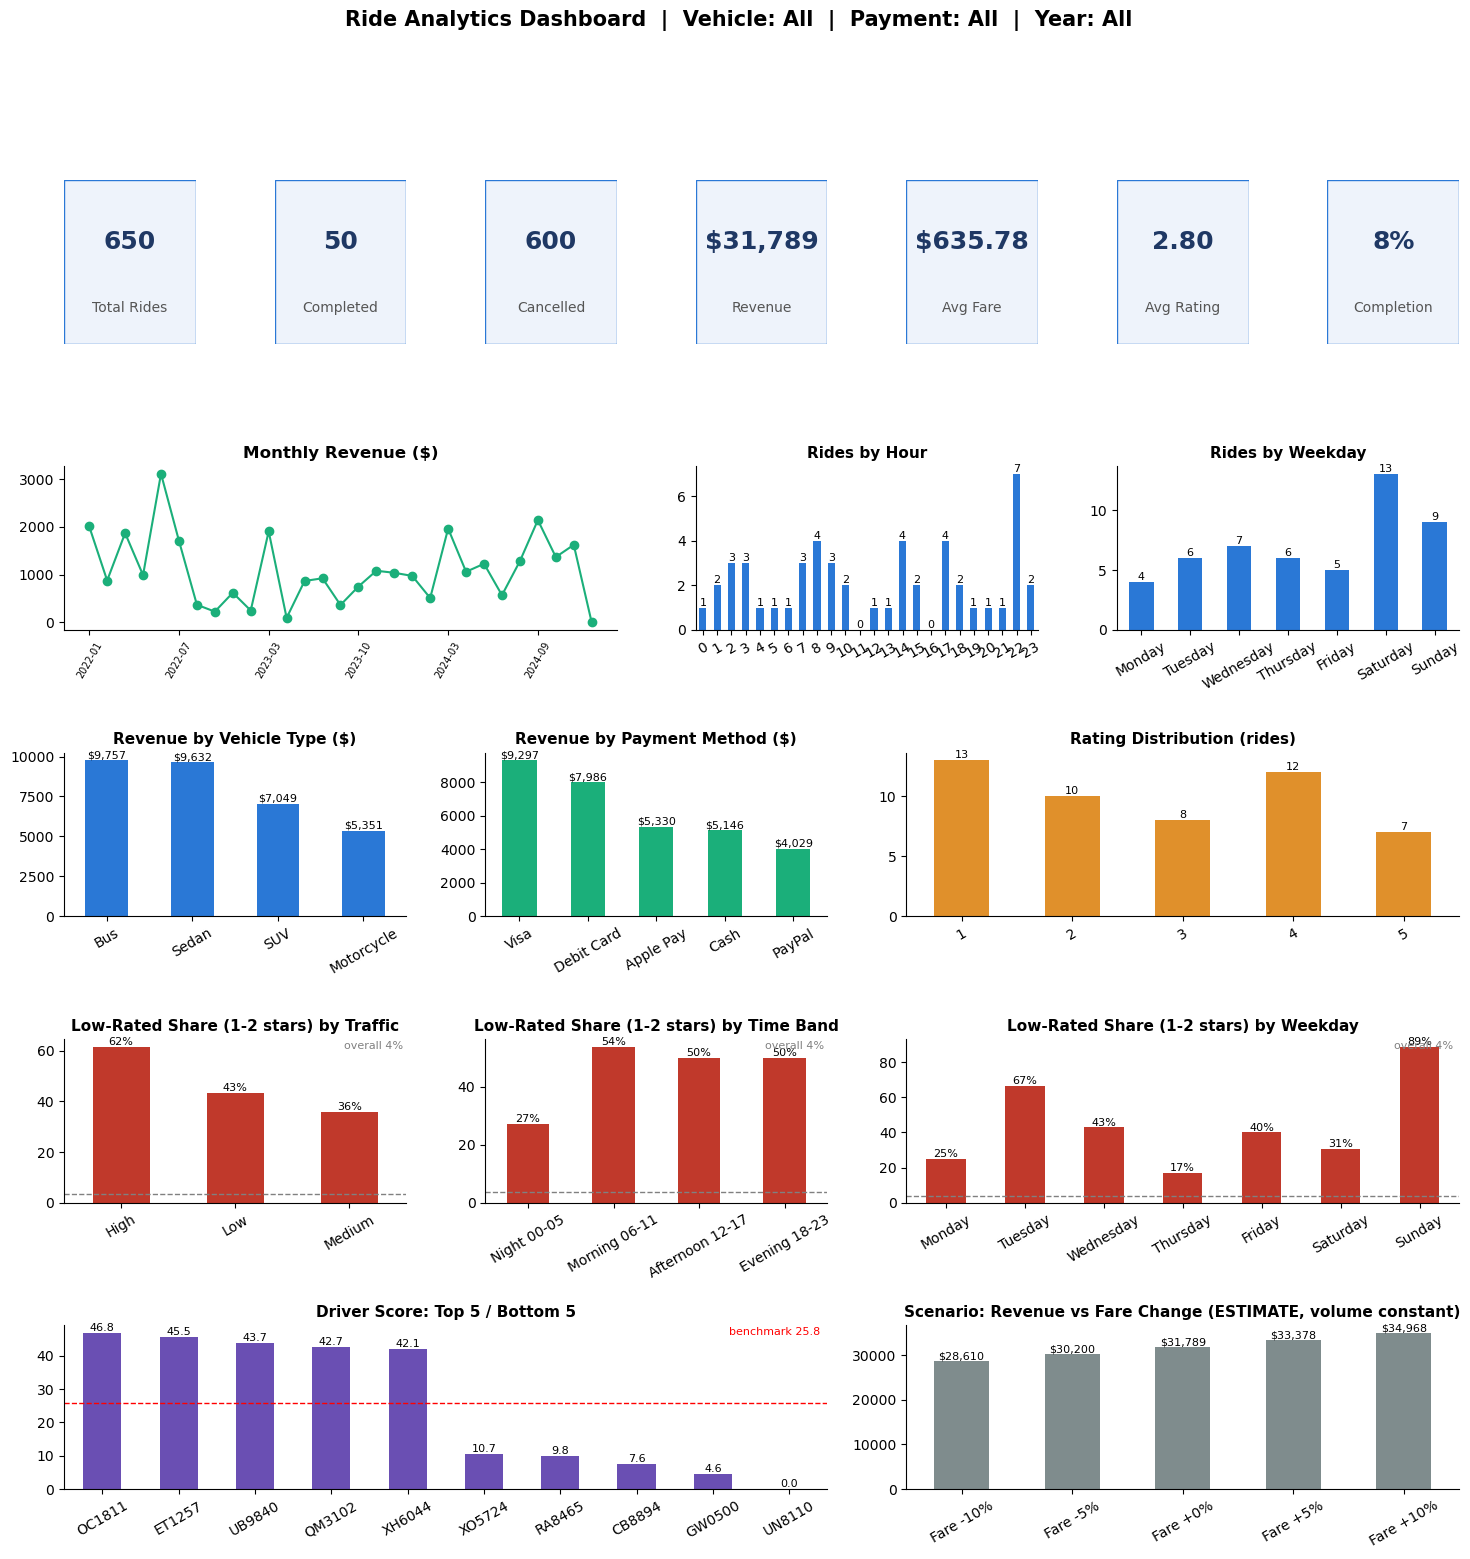

Driver table (top 5 / bottom 5; benchmark score = 25.81):
Driver ID  Rides  Completed  Revenue  Rating  Completion %  Score
   OC1811      1          1   1159.1     4.0         100.0   46.8
   ET1257      1          1    867.3     5.0         100.0   45.5
   UB9840      1          1   1039.2     4.0         100.0   43.7
   QM3102      1          1    758.1     5.0         100.0   42.7
   XH6044      1          1    734.3     5.0         100.0   42.1
   XO5724      1          1    484.6     1.0         100.0   10.7
   RA8465      1          1    452.8     1.0         100.0    9.8
   CB8894      1          1    365.4     1.0         100.0    7.6
   GW0500      1          1    250.6     1.0         100.0    4.6
   UN8110      1          1     72.5     1.0         100.0    0.0

Notes: status is a proxy (fare > 0); each driver has 1 ride; scenarios are estimates; distances are implausible; associations are not causes.


In [20]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

FILE = "Ride_Sharing_Dataset_FIXED.csv"        # ride-level file, in the notebook folder
FARE, RATING, DIST = "Fare Amount (in $)", "User Rating", "Ride Distance (in miles)"

# ---------- 1. LOAD, AUDIT, PREPARE ----------
raw = pd.read_csv(FILE); raw.columns = raw.columns.str.strip()
need = ["Ride ID","Request Time","Driver ID",FARE,RATING,DIST,"Vehicle Type","Payment Method","Traffic Condition","Peak Hours"]
assert not [c for c in need if c not in raw.columns], "Wrong file: load the ride-level dataset"

df = raw.copy()
df["Request Time"] = pd.to_datetime(df["Request Time"], errors="coerce")
df["Year"] = df["Request Time"].dt.year
df["Month"] = df["Request Time"].dt.to_period("M").astype(str)
df["Weekday"] = df["Request Time"].dt.day_name()          # derived from timestamp
df["Hour"] = df["Request Time"].dt.hour
df["Time Band"] = pd.cut(df.Hour, [-1,5,11,17,23], labels=["Night 00-05","Morning 06-11","Afternoon 12-17","Evening 18-23"])
df["Completed"] = df[FARE] > 0                            # proxy status: fare > 0
df["Low Rated"] = df[RATING] <= 2
WEEK = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

audit = pd.Series({
    "Rows": len(df), "Missing values": int(df.isnull().sum().sum()),
    "Duplicate Ride IDs": int(df["Ride ID"].duplicated().sum()),
    "Invalid dates": int(df["Request Time"].isna().sum()),
    "Zero/negative fares": int((df[FARE] <= 0).sum()),
    "Invalid ratings": int((~df[RATING].between(1,5)).sum()),
    "Distances over 500 miles": int((df[DIST] > 500).sum()),
    "Stored Day of Week matches timestamp (%)": round((df.Weekday == df["Day of Week"]).mean()*100) if "Day of Week" in df else None})

# ---------- 2. DRIVER SCORE (benchmark from the full data) ----------
def norm(s, lo=None, hi=None):
    lo = s.min() if lo is None else lo; hi = s.max() if hi is None else hi
    return (s-lo)/(hi-lo) if hi != lo else s*0

def driver_table(d):
    t = d.groupby("Driver ID").agg(Rides=(FARE,"count"), Completed=("Completed","sum"),
                                   Revenue=(FARE,"sum"), Rating=(RATING,"mean")).reset_index()
    t["Completion %"] = t.Completed/t.Rides*100
    t["Score"] = 100*(0.30*norm(t.Revenue)+0.25*norm(t.Rides)+0.25*norm(t.Rating,1,5)+0.20*norm(t["Completion %"]))
    return t.sort_values("Score", ascending=False).reset_index(drop=True)

drivers_all = driver_table(df)
BENCH = drivers_all.Score.mean()

# ---------- 3. DASHBOARD ----------
def dashboard(vehicle="All", payment="All", year="All", show_tables=True):
    d = df.copy()
    if vehicle != "All": d = d[d["Vehicle Type"] == vehicle]
    if payment != "All": d = d[d["Payment Method"] == payment]
    if year != "All":    d = d[d.Year == int(year)]
    if d.empty: print("No rides match these filters."); return

    n, comp = len(d), int(d.Completed.sum()); rev = d.loc[d.Completed, FARE].sum()
    kpis = [("Total Rides", f"{n}"), ("Completed", f"{comp}"), ("Cancelled", f"{n-comp}"),
            ("Revenue", f"${rev:,.0f}"), ("Avg Fare", f"${rev/max(comp,1):,.2f}"),
            ("Avg Rating", f"{d[RATING].mean():.2f}"), ("Completion", f"{comp/n:.0%}")]

    fig = plt.figure(figsize=(18, 17)); gs = GridSpec(5, 7, figure=fig, hspace=0.75, wspace=0.6)
    fig.suptitle(f"Ride Analytics Dashboard  |  Vehicle: {vehicle}  |  Payment: {payment}  |  Year: {year}",
                 fontsize=15, fontweight="bold")
    for i,(lab,val) in enumerate(kpis):                      # KPI cards
        ax = fig.add_subplot(gs[0, i]); ax.axis("off")
        ax.add_patch(plt.Rectangle((0,0),1,1,transform=ax.transAxes,fc="#eef3fb",ec="#2a78d6"))
        ax.text(.5,.62,val,ha="center",va="center",fontsize=18,fontweight="bold",color="#1f3864",transform=ax.transAxes)
        ax.text(.5,.22,lab,ha="center",va="center",fontsize=10,color="#555",transform=ax.transAxes)

    def bar(ax, s, title, color="#2a78d6", fmt="${:,.0f}", h=False):
        s.plot.barh(ax=ax, color=color) if h else s.plot.bar(ax=ax, color=color, rot=30)
        ax.set_title(title, fontsize=11, fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
        for p in ax.patches:
            v = p.get_width() if h else p.get_height()
            ax.annotate(fmt.format(v), (v if h else p.get_x()+p.get_width()/2, p.get_y()+p.get_height()/2 if h else v),
                        ha="left" if h else "center", va="center" if h else "bottom", fontsize=8)
        ax.spines[["top","right"]].set_visible(False)

    m = d.groupby("Month")[FARE].sum()                       # demand row
    ax = fig.add_subplot(gs[1, 0:3]); m.plot(ax=ax, marker="o", color="#1baf7a"); ax.set_title("Monthly Revenue ($)", fontweight="bold")
    ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=7, rotation=60); ax.spines[["top","right"]].set_visible(False)
    bar(fig.add_subplot(gs[1, 3:5]), d.Hour.value_counts().reindex(range(24), fill_value=0), "Rides by Hour", fmt="{:.0f}")
    bar(fig.add_subplot(gs[1, 5:7]), d.Weekday.value_counts().reindex(WEEK, fill_value=0), "Rides by Weekday", fmt="{:.0f}")

    bar(fig.add_subplot(gs[2, 0:2]), d.groupby("Vehicle Type")[FARE].sum().sort_values(ascending=False), "Revenue by Vehicle Type ($)")
    bar(fig.add_subplot(gs[2, 2:4]), d.groupby("Payment Method")[FARE].sum().sort_values(ascending=False), "Revenue by Payment Method ($)", "#1baf7a")
    bar(fig.add_subplot(gs[2, 4:7]), d[RATING].value_counts().reindex(range(1,6), fill_value=0), "Rating Distribution (rides)", "#e0902b", "{:.0f}")

    overall = d["Low Rated"].mean()*100                       # operations row: low-rated share
    for j,(col,ttl) in enumerate([("Traffic Condition","Traffic"),("Time Band","Time Band"),("Weekday","Weekday")]):
        s = d.groupby(col, observed=True)["Low Rated"].mean()*100
        if col == "Weekday": s = s.reindex([w for w in WEEK if w in s.index])
        ax = fig.add_subplot(gs[3, [0,2,4][j]:[2,4,7][j]])
        bar(ax, s, f"Low-Rated Share (1-2 stars) by {ttl}", "#c0392b", "{:.0f}%")
        ax.axhline(overall, ls="--", color="grey", lw=1); ax.text(0.99, 0.94, f"overall {overall:.0f}%", transform=ax.transAxes, ha="right", fontsize=8, color="grey")

    dr = drivers_all[drivers_all["Driver ID"].isin(d["Driver ID"])]    # drivers + scenario
    sel = pd.concat([dr.head(5), dr.tail(5)]).drop_duplicates("Driver ID")
    ax = fig.add_subplot(gs[4, 0:4]); bar(ax, sel.set_index("Driver ID").Score, "Driver Score: Top 5 / Bottom 5", "#6a4fb3", "{:.1f}")
    ax.axhline(BENCH, ls="--", color="red", lw=1); ax.text(0.99, 0.94, f"benchmark {BENCH:.1f}", transform=ax.transAxes, ha="right", fontsize=8, color="red")
    sc = pd.Series({f"Fare {p:+.0%}": rev*(1+p) for p in (-0.10,-0.05,0,0.05,0.10)})
    bar(fig.add_subplot(gs[4, 4:7]), sc, "Scenario: Revenue vs Fare Change (ESTIMATE, volume constant)", "#7f8c8d")
    plt.show()

    if show_tables:
        print("Driver table (top 5 / bottom 5; benchmark score = %.2f):" % BENCH)
        print(sel[["Driver ID","Rides","Completed","Revenue","Rating","Completion %","Score"]].round(1).to_string(index=False))
        print("\nNotes: status is a proxy (fare > 0); each driver has 1 ride; scenarios are estimates; "
              "distances are implausible; associations are not causes.")

print(audit.to_string())
dashboard()          # unfiltered view

In [21]:
try:
    import ipywidgets as w
    w.interact(dashboard,
               vehicle=["All"] + sorted(df["Vehicle Type"].unique()),
               payment=["All"] + sorted(df["Payment Method"].unique()),
               year=["All"] + [str(y) for y in sorted(df.Year.dropna().unique().astype(int))],
               show_tables=True)
except ImportError:
    print("Install ipywidgets (pip install ipywidgets) for dropdown filters, or call e.g. dashboard('Sedan', 'Visa', 'All')")

TypeError: '<' not supported between instances of 'float' and 'str'

In [22]:
try:
    import ipywidgets as w
    w.interact(
        dashboard,
        vehicle=["All"] + sorted([str(x) for x in df["Vehicle Type"].dropna().unique()]),
        payment=["All"] + sorted([str(x) for x in df["Payment Method"].dropna().unique()]),
        year=["All"] + [str(y) for y in sorted(df.Year.dropna().unique().astype(int))],
        show_tables=True
    )
except ImportError:
    print("Install ipywidgets (pip install ipywidgets) for dropdown filters, or call e.g. dashboard('Sedan', 'Visa', 'All')")

interactive(children=(Dropdown(description='vehicle', options=('All', 'Bus', 'Motorcycle', 'SUV', 'Sedan'), va…

In [23]:
# Assuming your dashboard function returns a DataFrame or you have a specific filtered dataframe:
# Example: Saving your driver table or filtered data to CSV
filtered_df = df.copy()  # or your filtered dataframe from the dashboard logic
filtered_df.to_csv("saved_dashboard_data.csv", index=False)
print("Dashboard data saved successfully!")

Dashboard data saved successfully!


In [24]:
from IPython.display import Javascript

# This executes the save command inside JupyterLab / Notebook
display(Javascript("IPython.notebook.save_checkpoint();"))

<IPython.core.display.Javascript object>

In [25]:
import matplotlib.pyplot as plt

# After generating your plot:
plt.savefig("my_dashboard.png", dpi=300, bbox_inches="tight")
print("Dashboard saved as image!")

Dashboard saved as image!


<Figure size 640x480 with 0 Axes>

In [26]:
# Save the currently filtered table data to a CSV file
filtered_df = df.copy() # Replace with your filtered dataframe if applicable
filtered_df.to_csv("my_dashboard_table.csv", index=False)
print("Table successfully saved as CSV!")

Table successfully saved as CSV!
